In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
import sys, os
# add the repo root (the folder containing config.py) to the path, from any depth
_root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_root, "config.py")) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)

In [4]:

import config, pandas as pd
from cprics.io_data import load_peak_amplitudes

CH = "9_top_right"      # 9 m wavelength, right rail (the dominant band in our data)
pk = load_peak_amplitudes(config.PEAK_AMP_DIR, CH)

print("rows (peaks):", len(pk))
print("date range:", pk['date'].min().date(), "->", pk['date'].max().date(),
      "| distinct dates:", pk['date'].nunique())
print("ELR/Track sections:", pk.groupby(['ELR','TrackID']).ngroups)
print("\namplitude (mm):\n", pk['amplitude'].describe().round(2).to_string())
print(f"\nsub-threshold peaks (<18 mm): {(pk['amplitude'] < 18).mean()*100:.0f}%")
pk.head()

rows (peaks): 445451
date range: 2025-01-12 -> 2026-10-03 | distinct dates: 67
ELR/Track sections: 49

amplitude (mm):
 count    445451.00
mean          1.38
std           1.26
min           0.00
25%           0.51
50%           0.99
75%           1.83
max          13.45

sub-threshold peaks (<18 mm): 100%


,ELR,TrackID,Location_m,Date,amplitude,date
0,BEN,2100,7267.8936,2025-06-29,0.411979,2025-06-29
1,BEN,2100,7272.8164,2025-06-29,0.405577,2025-06-29
2,BEN,2100,7281.4224,2025-06-29,3.206561,2025-06-29
3,BEN,2100,7290.3260,2025-06-29,4.435286,2025-06-29
4,BEN,2100,7300.5933,2025-06-29,2.982223,2025-06-29


In [5]:
strong = pk[pk.amplitude >= 5]          # 5 mm = the cyclic-top peak threshold
print("peaks >=5mm:", len(strong), f"({len(strong)/len(pk)*100:.1f}% of all peaks)")
print("sections with >=5mm peaks:", strong.groupby(['ELR','TrackID']).ngroups)
print(strong.groupby(['ELR','TrackID']).size().sort_values(ascending=False).head(10))

peaks >=5mm: 9813 (2.2% of all peaks)
sections with >=5mm peaks: 42
ELR   TrackID
CDM2  2100       1389
NMC1  3400        997
CNB1  1100        900
CRR1  2100        764
CRR2  1100        727
CHW1  1100        612
CNB3  3400        539
RSJ   2100        448
CWK2  2100        377
BTH1  1100        323
dtype: int64


count     9172.00
mean       363.29
std       1083.51
min          1.00
25%          9.28
50%         10.36
75%        209.25
max      15014.88
Name: Location_m, dtype: float64


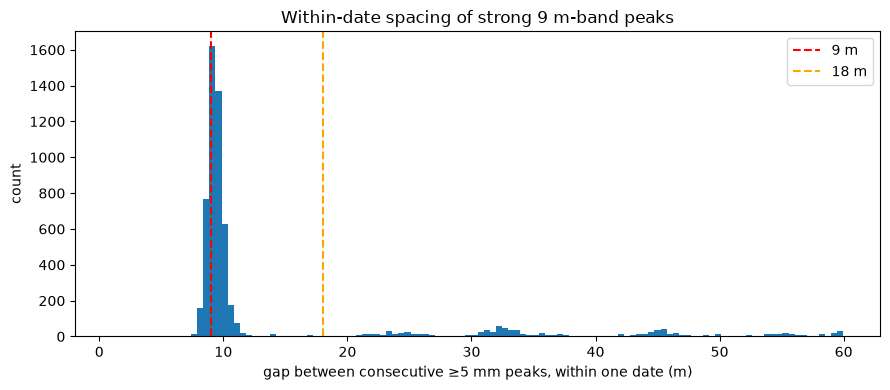

In [6]:
import matplotlib.pyplot as plt
strong = pk[pk.amplitude >= 5].sort_values(["ELR", "TrackID", "date", "Location_m"])
gaps = strong.groupby(["ELR", "TrackID", "date"])["Location_m"].diff().dropna()
gaps = gaps[gaps > 0]
print(gaps.describe().round(2))
plt.figure(figsize=(9, 4))
plt.hist(gaps[gaps < 60], bins=120)
for x, c in [(9, "red"), (18, "orange")]:
    plt.axvline(x, color=c, ls="--", label=f"{x} m")
plt.xlabel("gap between consecutive ≥5 mm peaks, within one date (m)")
plt.ylabel("count"); plt.title("Within-date spacing of strong 9 m-band peaks")
plt.legend(); plt.tight_layout(); plt.show()